### Utils

In [1]:
import torch

In [2]:
def build_dataset(df):
    grouped = df.groupby("ecg_id")

    X = []
    y = []

    for _, group in grouped:
        signal = group[[f'channel-{i}' for i in range(12)]].values
        label = group[['NORM','MI','STTC','HYP','CD']].iloc[0].values

        X.append(signal)
        y.append(label)

    return np.array(X), np.array(y)

In [3]:
MAX_LEN = 1000 

def pad_signal(x):
    if len(x) > MAX_LEN:
        return x[:MAX_LEN]
    else:
        pad = np.zeros((MAX_LEN - len(x), x.shape[1]))
        return np.vstack([x, pad])

In [4]:
class ECGDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [5]:
def loop_fn(mode, dataset, dataloader, model, criterion, optimizer, device):
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()

    cost = 0
    pbar = tqdm(dataloader, total=len(dataloader), desc=mode.title())
    
    for feature, target in pbar:
        feature, target = feature.to(device), target.to(device)
        output = model(feature)
        loss = criterion(output, target)

        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        cost += loss.item() * feature.shape[0]
    cost = cost / len(dataset)
    return cost

In [6]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score

def evaluate_model(model, dataloader, device, threshold=0.5):
    model.eval()
    
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            probs = model(X_batch)  # output sigmoid (0-1)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.numpy())

    # gabungkan semua batch
    probs = np.vstack(all_probs)
    targets = np.vstack(all_targets)

    # thresholding → jadi prediksi 0/1
    y_pred = (probs > threshold).astype(int)

    # =====================
    # F1 Score
    # =====================
    f1_micro = f1_score(targets, y_pred, average='micro')
    f1_macro = f1_score(targets, y_pred, average='macro')

    # =====================
    # AUROC
    # =====================
    try:
        auc_macro = roc_auc_score(targets, probs, average='macro')
    except:
        auc_macro = None  # kalau ada label yang tidak muncul

    return {
        "f1_micro": f1_micro,
        "f1_macro": f1_macro,
        "auc_macro": auc_macro
    }

## Train

In [7]:
import sys
import os
sys.path.append(os.path.abspath('../code'))

from models.xresnet1d import xresnet1d101
from models.resnet1d import resnet1d_wang, wrn1d_22
from models.inception1d import inception1d
from models.rnn1d import RNN1d

C:\Users\asus_\miniconda3\envs\dlenv\Lib\site-packages\fastai\imports\core.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [8]:
from torch.utils.data import DataLoader
import pandas as pd
import numpy as np
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [9]:
train = pd.read_csv("gabungannya_train_lr.csv")
valid = pd.read_csv("gabungannya_valid_lr.csv")

In [10]:
X_train, y_train = build_dataset(train)
X_val, y_val = build_dataset(valid)

In [11]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((17418, 1000, 12), (2198, 1000, 12), (17418, 5), (2198, 5))

In [12]:
X_train = np.transpose(X_train, (0, 2, 1))
X_val   = np.transpose(X_val, (0, 2, 1))

In [13]:
train_dataset = ECGDataset(X_train, y_train)
val_dataset   = ECGDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [14]:
X_val.shape

(2198, 12, 1000)

In [15]:
from torch import optim, nn
from tqdm.auto import tqdm
from jcopdl.callback import Callback

# Training Preparation

### RNN

In [16]:
rnn = RNN1d(input_channels=12, num_classes=5).to(device)

In [17]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(rnn.parameters(), lr=1e-3)
callback = Callback(rnn, outdir="RNN")

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     1
Train_cost  = 0.4419 | Test_cost  = 0.4270 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     2
Train_cost  = 0.3637 | Test_cost  = 0.3574 | 


... (50 outputs left out)


Epoch    19
Train_cost  = 0.2462 | Test_cost  = 0.2916 | 
==> EarlyStop patience =  1 | Best test_cost: 0.2807


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    20
Train_cost  = 0.2436 | Test_cost  = 0.2795 | 


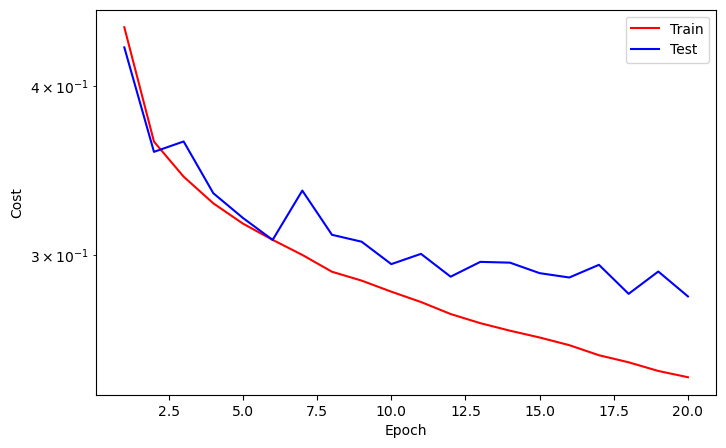

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    21
Train_cost  = 0.2395 | Test_cost  = 0.2858 | 
==> EarlyStop patience =  1 | Best test_cost: 0.2795


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    22
Train_cost  = 0.2355 | Test_cost  = 0.2856 | 
==> EarlyStop patience =  2 | Best test_cost: 0.2795


... (5 outputs left out)


Epoch    24
Train_cost  = 0.2278 | Test_cost  = 0.2888 | 
==> EarlyStop patience =  4 | Best test_cost: 0.2795


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    25
Train_cost  = 0.2273 | Test_cost  = 0.2838 | 
==> EarlyStop patience =  5 | Best test_cost: 0.2795
==> Execute Early Stopping at epoch: 25 | Best test_cost: 0.2795
==> Best model is saved at RNN


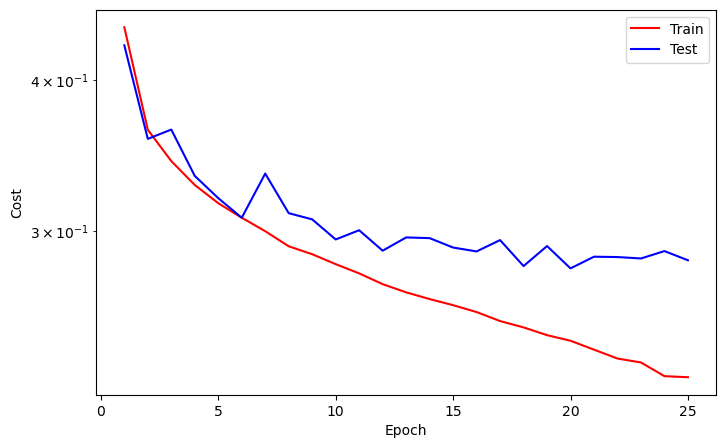

In [18]:
while True:
    train_cost = loop_fn("train", train_dataset, train_loader, rnn, criterion, optimizer, device)
    with torch.no_grad():
        test_cost = loop_fn("test", val_dataset, val_loader, rnn, criterion, optimizer, device)
        
    callback.log(train_cost, test_cost)
    callback.save_checkpoint()
    callback.cost_runtime_plotting()
    if callback.early_stopping(rnn, monitor='test_cost'):
        callback.plot_cost()
        break

In [19]:
metrics = evaluate_model(rnn, val_loader, device)

print(metrics)

{'f1_micro': 0.7407557082238836, 'f1_macro': 0.6973475097287991, 'auc_macro': 0.9205427916961322}
